In [46]:
import pandas as pd
import math

from IPython.display import Image

<h3>Classification tree — Gini · weighted Gini · gain</h3>

Displaying the table for better understanding of defining the variables - see Gini Table.png

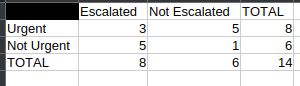

In [47]:
display(Image(filename="Gini Table.png"))

<h4>a</h4>

In [48]:
ticket_total = 14
ticket_esc = 8
ticket_not_esc = 6

g_parent = 1 - (((ticket_esc / ticket_total) ** 2) + ((ticket_not_esc / ticket_total) ** 2))
print('The Gini of the parent is ', g_parent)

The Gini of the parent is  0.48979591836734704


<h4>b</h4>

In [49]:
ticket_urgent = 8
ticket_urgent_esc = 3
ticket_urgent_nesc = 5

ticket_not_urgent = 6
ticket_nurgent_esc = 5
ticket_nurgent_nesc = 1

g_urgent = 1 - (((ticket_urgent_esc / ticket_urgent) ** 2) + ((ticket_urgent_nesc / ticket_urgent) ** 2))
print('The Gini of the urgent tickets is ', g_urgent)
print('----------------------------------')

g_not_urgent = 1 - (((ticket_nurgent_esc / ticket_not_urgent) ** 2) + ((ticket_nurgent_nesc / ticket_not_urgent) ** 2))
print('The Gini of the not urgent tickets is', g_not_urgent)


The Gini of the urgent tickets is  0.46875
----------------------------------
The Gini of the not urgent tickets is 0.2777777777777777


<h4>c</h4>

In [50]:
g_weighted = ((ticket_urgent / ticket_total) * g_urgent) + ((ticket_not_urgent / ticket_total) * g_not_urgent)
print ('Weighted impurity is', g_weighted)
print('----------------------------------')

g_gain = g_parent - g_weighted
print ('The Gain is', g_gain)


Weighted impurity is 0.38690476190476186
----------------------------------
The Gain is 0.10289115646258518


<h4>d</h4>

The tree is asking what has a higher Gini score as it picks the split with the highest Gini Gain to create cleaner groups, leading to better predictions.

<h3>Regression tree — MSE · weighted MSE · gain</h3>

<h4>a</h4>

In [56]:
call_amount = 6
handling_time = [5, 7, 15, 17, 19, 21]
handling_time_total = 5 + 7 + 15 + 17 + 19 + 21
handling_time_mean = handling_time_total / call_amount

print('The mean handling time ( ˉy) is', handling_time_mean)
print('----------------------------------')

handling_time_sse = 0
for y in handling_time:
    handling_time_sse += (y - handling_time_mean) ** 2

print('The handling time SSE is', handling_time_sse)
print('----------------------------------')

print('The handling time MSE is', (1 / call_amount) * handling_time_sse)

The mean handling time ( ˉy) is 14.0
----------------------------------
The handling time SSE is 214.0
----------------------------------
The handling time MSE is 35.666666666666664


<h4>b</h4>

In [57]:
issues = [1, 2, 4, 5, 7, 8]
handling_time_left = []
handling_time_right = []
calls_left = 0
calls_right = 0
for i in range(call_amount):
    if issues[i] <= 3:
        handling_time_left.append(handling_time[i])
        calls_left += 1
    else:
        handling_time_right.append(handling_time[i])
        calls_right += 1

handling_time_left_total = 0
for y in handling_time_left:
    handling_time_left_total += y
handling_time_left_mean = handling_time_left_total / calls_left

handling_time_left_sse = 0
for y in handling_time_left:
    handling_time_left_sse += (y - handling_time_left_mean) ** 2

print('The handling time left mean is', handling_time_left_mean)
print('The handling time left SSE is', handling_time_left_sse)
print('The handling time left MSE is', (1 / calls_left) * handling_time_left_sse)
print('----------------------------------')

handling_time_right_total = 0
for y in handling_time_right:
    handling_time_right_total += y
handling_time_right_mean = handling_time_right_total / calls_right

handling_time_right_sse = 0
for y in handling_time_right:
    handling_time_right_sse += (y - handling_time_right_mean) ** 2


print('The handling time right mean is', handling_time_right_mean)
print('The handling time right SSE is', handling_time_right_sse)
print('The handling time right MSE is', (1 / calls_right) * handling_time_right_sse)
print('----------------------------------')

handling_time_weighted_mse = (calls_left / call_amount) * handling_time_left_mse + (calls_right / call_amount) * handling_time_right_mse
handling_time_gain = handling_time_mse - handling_time_weighted_mse

print('The handling time weighted MSE is', handling_time_weighted_mse)
print('The handling time gain is', handling_time_gain)

The handling time left mean is 6.0
The handling time left SSE is 2.0
The handling time left MSE is 1.0
----------------------------------
The handling time right mean is 18.0
The handling time right SSE is 20.0
The handling time right MSE is 5.0
----------------------------------
The handling time weighted MSE is 3.6666666666666665
The handling time gain is 31.999999999999996


<h4>c</h4>

In [58]:
premium = ['no', 'yes', 'no', 'yes', 'yes', 'yes']

handling_time_no = []
handling_time_yes = []
calls_no = 0
calls_yes = 0
for i in range(call_amount):
    if premium[i] == 'no':
        handling_time_no.append(handling_time[i])
        calls_no += 1
    else:
        handling_time_yes.append(handling_time[i])
        calls_yes += 1

handling_time_no_total = 0
for y in handling_time_no:
    handling_time_no_total += y
handling_time_no_mean = handling_time_no_total / calls_no

handling_time_no_sse = 0
for y in handling_time_no:
    handling_time_no_sse += (y - handling_time_no_mean) ** 2

print('The handling time no mean is', handling_time_no_mean)
print('The handling time no SSE is', handling_time_no_sse)
print('The handling time no MSE is', (1 / calls_no) * handling_time_no_sse)
print('----------------------------------')

handling_time_yes_total = 0
for y in handling_time_yes:
    handling_time_yes_total += y
handling_time_yes_mean = handling_time_yes_total / calls_yes

handling_time_yes_sse = 0
for y in handling_time_yes:
    handling_time_yes_sse += (y - handling_time_yes_mean) ** 2

print('The handling time yes mean is', handling_time_yes_mean)
print('The handling time yes SSE is', handling_time_yes_sse)
print('The handling time yes MSE is', (1 / calls_yes) * handling_time_yes_sse)
print('----------------------------------')

handling_time_weighted_mse_b = (calls_no / call_amount) * handling_time_no_mse + (calls_yes / call_amount) * handling_time_yes_mse
handling_time_gain_b = handling_time_mse - handling_time_weighted_mse_b

print('The handling time weighted MSE is', handling_time_weighted_mse_b)
print('The handling time gain is', handling_time_gain_b)

The handling time no mean is 10.0
The handling time no SSE is 50.0
The handling time no MSE is 25.0
----------------------------------
The handling time yes mean is 16.0
The handling time yes SSE is 116.0
The handling time yes MSE is 29.0
----------------------------------
The handling time weighted MSE is 27.666666666666664
The handling time gain is 8.0


<h4>d</h4>

The first split, issues ≤ 3, has the larger gain (32 vs 8), so the tree splits on issues ≤ 3. Each leaf predicts its mean handling time
- Left issues ≤ 3 is 6
- Right issues > 3 is 18